# Modélisation du prix des billets d'avion


## Importation des bibliothèques


In [104]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, cross_validate, GridSearchCV
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler, FunctionTransformer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, root_mean_squared_error, r2_score
import joblib
import os
import matplotlib.pyplot as plt
import seaborn as sns


## Chargement des données


In [75]:
data = pd.read_csv('../data/dataset.csv')
data = data.drop(columns=['Unnamed: 0', 'flight'])
data.head()

,airline,source_city,departure_time,stops,arrival_time,destination_city,class,duration,days_left,price
0,SpiceJet,Delhi,Evening,zero,Night,Mumbai,Economy,2.17,1,5953
1,SpiceJet,Delhi,Early_Morning,zero,Morning,Mumbai,Economy,2.33,1,5953
2,AirAsia,Delhi,Early_Morning,zero,Early_Morning,Mumbai,Economy,2.17,1,5956
3,Vistara,Delhi,Morning,zero,Afternoon,Mumbai,Economy,2.25,1,5955
4,Vistara,Delhi,Morning,zero,Morning,Mumbai,Economy,2.33,1,5955


## Préparation des données


In [76]:
X = data.drop(columns=['price'])
Y = data['price']

## Séparation des données d'entraînement et de test


In [77]:
X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.2, random_state=42
)

# Préprocessing


## Définition des groupes de variables


In [78]:
nominal_cols = ['airline', 'source_city', 'destination_city']
ordinal_cols = ['departure_time', 'stops', 'arrival_time', 'class']
numeric_cols = ['duration', 'days_left']

## Création des encodeurs


In [79]:
time_order = ['Early_Morning', 'Morning', 'Afternoon', 'Evening', 'Night', 'Late_Night']
stops_order = ['zero', 'one', 'two_or_more']
class_order = ['Economy', 'Business']

onehot = OneHotEncoder(handle_unknown='ignore', sparse_output=False)

ordinal = OrdinalEncoder(
    categories=[time_order, stops_order, time_order, class_order],
    handle_unknown='use_encoded_value',
    unknown_value=-1
)

## Transformation de la durée


In [80]:
log_duration = FunctionTransformer(np.log1p, feature_names_out='one-to-one')

## Création du préprocesseur


In [81]:
scaler = StandardScaler()

preprocessor = ColumnTransformer(
    transformers=[
        ('nominal', onehot, nominal_cols),
        ('ordinal', ordinal, ordinal_cols),
        ('log_duration', log_duration, ['duration']),
        ('scaler', scaler, ['days_left']),
    ]
)

# Modélisation


## Définition des métriques d'évaluation

In [82]:
scoring = {
    'RMSE': 'neg_root_mean_squared_error',
    'MAE': 'neg_mean_absolute_error',
    'R2': 'r2'
}

## Régression linéaire


### Création du pipeline

In [83]:
pipeline_lr = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', LinearRegression())
])


### Validation croisée

In [84]:
cv_lr = cross_validate(pipeline_lr, X_train, Y_train, cv=5, scoring=scoring, n_jobs=-1)

resultats_folds_lr = pd.DataFrame({
    'Fold': [1, 2, 3, 4, 5],
    'MAE': -cv_lr['test_MAE'],
    'RMSE': -cv_lr['test_RMSE'],
    'R²': cv_lr['test_R2']
})

resultats_folds_lr.round(2)

,Fold,MAE,RMSE,R²
0,1,4530.12,6750.76,0.91
1,2,4537.23,6761.80,0.91
2,3,4567.31,6831.63,0.91
3,4,4556.52,6811.57,0.91
4,5,4520.67,6773.79,0.91


### Interprétation

Les résultats sont similaires sur les 5 folds, avec un R² autour de 0,91.  
Le modèle présente donc une bonne stabilité lors de la validation croisée.

## Régression Ridge


### Création du pipeline

In [85]:
pipeline_ridge = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', Ridge(random_state=42))
])

### Recherche le meilleur alpha

In [86]:
alphas = np.logspace(-4, 4, 20)

param_grid_ridge = {
    'regressor__alpha': alphas
}

grid_ridge = GridSearchCV(
    pipeline_ridge,
    param_grid=param_grid_ridge,
    cv=5,
    scoring=scoring,
    refit='RMSE',
    n_jobs=-1
)

grid_ridge.fit(X_train, Y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.",{'regressor__alpha': array([ 0....000. ])}
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.","{'MAE': 'neg_mean_absolute_error', 'R2': 'r2', 'RMSE': 'neg_root_mean_squared_error'}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",'RMSE'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verb

In [112]:
from sklearn.utils import estimator_html_repr
from pathlib import Path

pipeline = grid_ridge.best_estimator_

html = estimator_html_repr(pipeline)

path = Path("../images/ml_pipeline.html")
path.parent.mkdir(parents=True, exist_ok=True)

path.write_text(html, encoding="utf-8")
print(path.resolve())

C:\Users\Youcode\Desktop\projects_python\predire_prix_billets_avion\images\ml_pipeline.html


### Recherche des meilleurs hyperparamètres de Ridge

In [87]:
print("Best alpha:", grid_ridge.best_params_['regressor__alpha'])
print("Best CV RMSE:", -grid_ridge.best_score_)

Best alpha: 0.03359818286283781
Best CV RMSE: 6785.911416761939


### Interprétation
Le meilleur modèle Ridge utilise un **alpha de 0.0336** et obtient un RMSE moyen de **6785.91** en validation croisée.

## Arbre de décision


### Création du pipeline

In [88]:
pipeline_tree = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', DecisionTreeRegressor(random_state=42))
])

### Validation croisée

In [89]:
param_grid_tree = {
    'regressor__max_depth': [5, 10, 15, 20, None],
    'regressor__min_samples_split': [2, 5, 10],
    'regressor__min_samples_leaf': [1, 2, 5]
}

grid_tree = GridSearchCV(
    pipeline_tree,
    param_grid=param_grid_tree,
    cv=5,
    scoring=scoring,
    refit='RMSE',
    n_jobs=-1
)

grid_tree.fit(X_train, Y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'regressor__max_depth': [5, 10, ...], 'regressor__min_samples_leaf': [1, 2, ...], 'regressor__min_samples_split': [2, 5, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.","{'MAE': 'neg_mean_absolute_error', 'R2': 'r2', 'RMSE': 'neg_root_mean_squared_error'}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",'RMSE'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... vers

### Recherche des meilleurs hyperparamètres de l'arbre


In [90]:
print("Meilleurs paramètres:", grid_tree.best_params_)
print("Best CV RMSE:", -grid_tree.best_score_)

Meilleurs paramètres: {'regressor__max_depth': None, 'regressor__min_samples_leaf': 5, 'regressor__min_samples_split': 2}
Best CV RMSE: 3006.2207560156103


### Interprétation

Le meilleur arbre utilise `max_depth=None`, `min_samples_leaf=5` et `min_samples_split=2`. Il obtient un RMSE moyen de **3006.22** en validation croisée.

## Random Forest


### Création du pipeline

In [91]:
pipeline_rf = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', RandomForestRegressor(random_state=42))
])

### Validation croisée

In [92]:
param_grid_rf = {
    'regressor__n_estimators': [100, 200],
    'regressor__max_depth': [None, 20],
    'regressor__min_samples_split': [2, 5],
    'regressor__min_samples_leaf': [1, 2],
    'regressor__max_features': [1.0, 'sqrt']
}

grid_rf = GridSearchCV(
    pipeline_rf,
    param_grid=param_grid_rf,
    cv=5,
    scoring=scoring,
    refit='RMSE',
    n_jobs=-1
)

grid_rf.fit(X_train, Y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'regressor__max_depth': [None, 20], 'regressor__max_features': [1.0, 'sqrt'], 'regressor__min_samples_leaf': [1, 2], 'regressor__min_samples_split': [2, 5], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.","{'MAE': 'neg_mean_absolute_error', 'R2': 'r2', 'RMSE': 'neg_root_mean_squared_error'}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",'RMSE'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strat

## Recherche des meilleurs hyperparamètres du Random Forest


In [93]:
print("Meilleurs paramètres:", grid_rf.best_params_)
print("Best CV RMSE:", -grid_rf.best_score_)

Meilleurs paramètres: {'regressor__max_depth': None, 'regressor__max_features': 1.0, 'regressor__min_samples_leaf': 2, 'regressor__min_samples_split': 5, 'regressor__n_estimators': 200}
Best CV RMSE: 2688.9240335313652


### Interprétation

La meilleure configuration du Random Forest utilise 200 arbres, avec `max_depth=None`, `max_features=1.0`, `min_samples_leaf=2` et `min_samples_split=5`.

Elle obtient un **RMSE moyen de 2688,92 en validation croisée** et sera utilisée pour la suite de l'évaluation.

# Comparaison des modèles


## Tableau comparatif des résultats


In [94]:
resultats_modeles = pd.DataFrame(
    {
        "Modele": [
            "Regression Lineaire",
            "Ridge",
            "Arbre de Decision",
            "Random Forest",
        ],
        "CV RMSE": [
            -cv_lr["test_RMSE"].mean(),
            -grid_ridge.cv_results_["mean_test_RMSE"][grid_ridge.best_index_],
            -grid_tree.cv_results_["mean_test_RMSE"][grid_tree.best_index_],
            -grid_rf.cv_results_["mean_test_RMSE"][grid_rf.best_index_],
        ],
        "CV MAE": [
            -cv_lr["test_MAE"].mean(),
            -grid_ridge.cv_results_["mean_test_MAE"][grid_ridge.best_index_],
            -grid_tree.cv_results_["mean_test_MAE"][grid_tree.best_index_],
            -grid_rf.cv_results_["mean_test_MAE"][grid_rf.best_index_],
        ],
        "CV R²": [
            cv_lr["test_R2"].mean(),
            grid_ridge.cv_results_["mean_test_R2"][grid_ridge.best_index_],
            grid_tree.cv_results_["mean_test_R2"][grid_tree.best_index_],
            grid_rf.cv_results_["mean_test_R2"][grid_rf.best_index_],
        ],
        "CV RMSE ecart-type": [
            cv_lr["test_RMSE"].std(),
            grid_ridge.cv_results_["std_test_RMSE"][grid_ridge.best_index_],
            grid_tree.cv_results_["std_test_RMSE"][grid_tree.best_index_],
            grid_rf.cv_results_["std_test_RMSE"][grid_rf.best_index_],
        ],
    }
)

resultats_modeles.round(2)

,Modele,CV RMSE,CV MAE,CV R²,CV RMSE ecart-type
0,Regression Lineaire,6785.91,4542.37,0.91,30.70
1,Ridge,6785.91,4542.37,0.91,30.70
2,Arbre de Decision,3006.22,1251.83,0.98,20.56
3,Random Forest,2688.92,1128.35,0.99,17.52


### Comparaison graphique des modèles : RMSE, MAE et R²

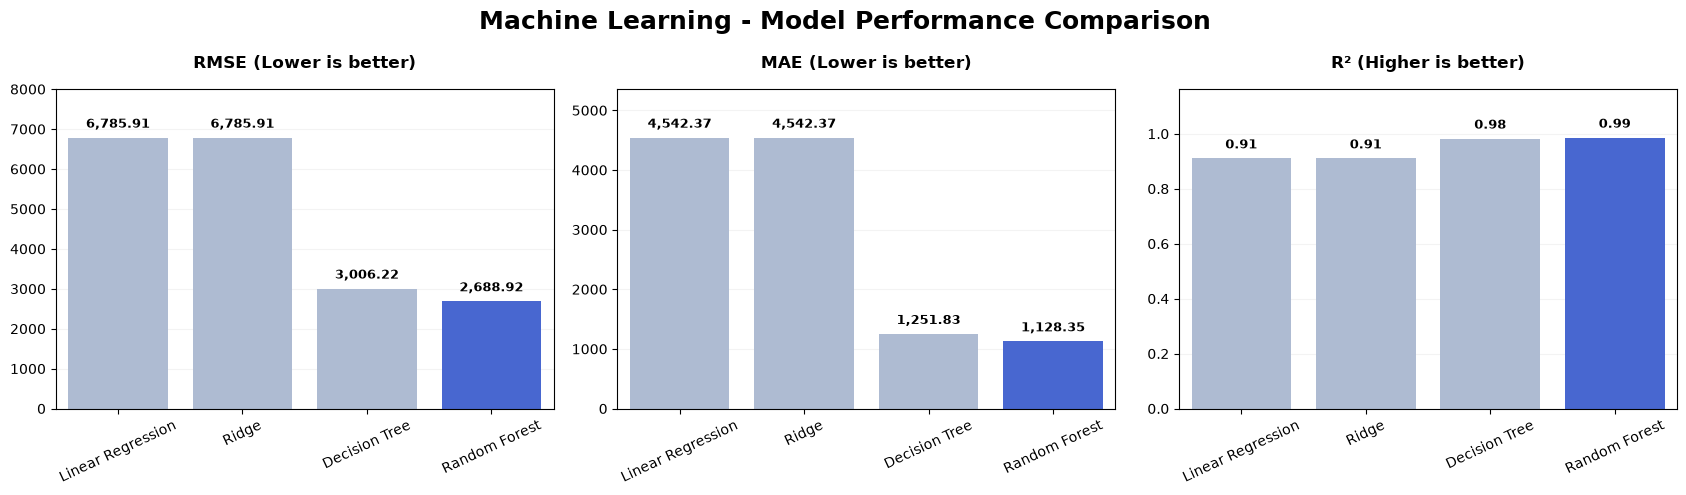

In [107]:
modeles = resultats_modeles.copy()

modeles["Modele"] = modeles["Modele"].replace({
    "Regression Lineaire": "Linear Regression",
    "Arbre de Decision": "Decision Tree"
})

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

metriques = [
    ("CV RMSE", "RMSE (Lower is better)"),
    ("CV MAE", "MAE (Lower is better)"),
    ("CV R²", "R² (Higher is better)")
]

couleurs = [
    "#315BE7" if modele == "Random Forest" else "#A8B9D8"
    for modele in modeles["Modele"]
]

for ax, (colonne, titre) in zip(axes, metriques):
    sns.barplot(
        data=modeles,
        x="Modele",
        y=colonne,
        hue="Modele",
        palette=dict(zip(modeles["Modele"], couleurs)),
        legend=False,
        ax=ax
    )

    ax.set_title(titre, fontsize=12, fontweight="bold", pad=15)
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.tick_params(axis="x", rotation=25)
    ax.grid(axis="y", alpha=0.15)
    ax.set_axisbelow(True)

    for barre in ax.patches:
        valeur = barre.get_height()
        ax.annotate(
            f"{valeur:,.2f}",
            (barre.get_x() + barre.get_width() / 2, valeur),
            ha="center",
            va="bottom",
            fontsize=9,
            fontweight="bold",
            xytext=(0, 5),
            textcoords="offset points"
        )

    ax.set_ylim(0, modeles[colonne].max() * 1.18)

fig.suptitle(
    "Machine Learning - Model Performance Comparison",
    fontsize=18,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


### Interprétation des résultats

Les modèles linéaires, Régression Linéaire et Ridge, obtiennent des performances similaires avec un RMSE d'environ 6785,91 et un R² de 0,91.

L'Arbre de Décision améliore fortement les performances avec un RMSE de 3006,22 et un R² de 0,98.

Le Random Forest obtient les meilleures performances avec :
- un RMSE de 2688,92 ;
- une MAE de 1128,35 ;
- un R² de 0,99 ;
- un écart-type du RMSE de 17,52.

Le Random Forest présente donc à la fois les erreurs les plus faibles, le R² le plus élevé et la meilleure stabilité entre les folds. Il est retenu comme meilleur modèle pour l'évaluation finale sur les données de test.

## Sélection du meilleur modèle


In [95]:
meilleur_modele = grid_rf.best_estimator_

### Prédictions sur le jeu de test


In [96]:
Y_test_pred = meilleur_modele.predict(X_test)

### Final Model Performance on the Test Set

In [97]:
resultats_test = pd.DataFrame({
    "MAE": [mean_absolute_error(Y_test, Y_test_pred)],
    "RMSE": [root_mean_squared_error(Y_test, Y_test_pred)],
    "R²": [r2_score(Y_test, Y_test_pred)]
})

resultats_test.round(2)

,MAE,RMSE,R²
0,1094.85,2687.42,0.99


### Actual vs. Predicted Ticket Prices

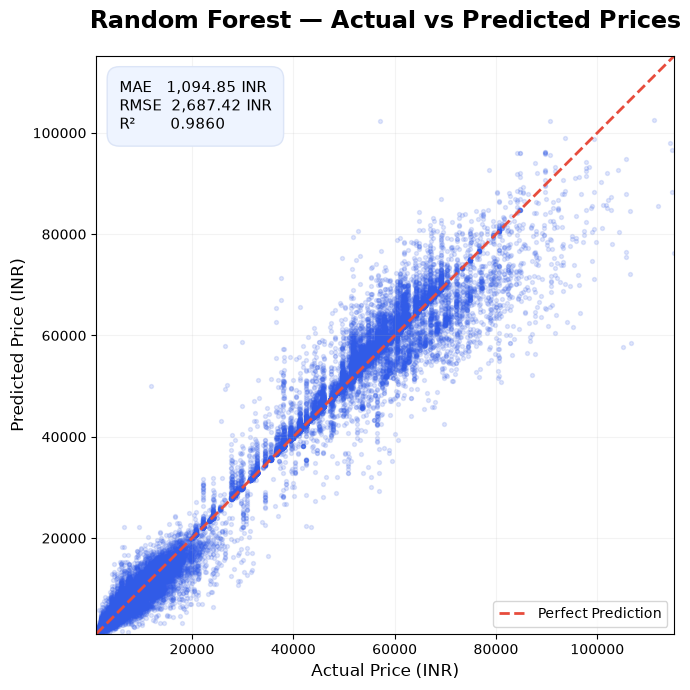

In [108]:
fig, ax = plt.subplots(figsize=(10, 7))

ax.scatter(
    Y_test,
    Y_test_pred,
    alpha=0.15,
    s=8,
    color="#315BE7"
)

limites = [
    min(Y_test.min(), Y_test_pred.min()),
    max(Y_test.max(), Y_test_pred.max())
]

ax.plot(
    limites,
    limites,
    color="#E74C3C",
    linestyle="--",
    linewidth=2,
    label="Perfect Prediction"
)

ax.set_title(
    "Random Forest — Actual vs Predicted Prices",
    fontsize=17,
    fontweight="bold",
    pad=20
)

ax.set_xlabel("Actual Price (INR)", fontsize=12)
ax.set_ylabel("Predicted Price (INR)", fontsize=12)

ax.set_xlim(limites)
ax.set_ylim(limites)
ax.set_aspect("equal", adjustable="box")

mae = resultats_test["MAE"].iloc[0]
rmse = resultats_test["RMSE"].iloc[0]
r2 = resultats_test["R²"].iloc[0]

texte = (
    f"MAE   {mae:,.2f} INR\n"
    f"RMSE  {rmse:,.2f} INR\n"
    f"R²       {r2:.4f}"
)

ax.text(
    0.04,
    0.96,
    texte,
    transform=ax.transAxes,
    fontsize=11,
    va="top",
    bbox=dict(
        boxstyle="round,pad=0.8",
        facecolor="#EEF4FF",
        edgecolor="#DCE5F7"
    )
)

ax.legend(loc="lower right")
ax.grid(alpha=0.15)

plt.tight_layout()
plt.show()


### Interprétation

Le Random Forest obtient de très bonnes performances sur le jeu de test, avec une **MAE de 1094,85**, un **RMSE de 2687,42** et un **R² de 0,99**.

Ces résultats sont très proches de ceux obtenus en validation croisée, notamment pour le RMSE (**2688,92 en CV contre 2687,42 sur le test**). Cela montre que le modèle généralise bien sur de nouvelles données et ne présente pas de signe important de surapprentissage.

## Export du modèle


### Export du pipeline final

In [98]:
os.makedirs("../artifacts", exist_ok=True)

joblib.dump(
    meilleur_modele,
    "../artifacts/flight_price_model.joblib"
)

['../artifacts/flight_price_model.joblib']